In [14]:
%matplotlib widget
import sys
import time
import chipwhisperer as cw
import numpy as np
import matplotlib.pyplot as plt
import struct

#FLASH_SIZE = 512 * 1024      # STM32L452RE: 512 KB
FLASH_SIZE = 256      # test
CHUNK = 64                   # SAM3U RX buffer holds only 128-200 bytes
BAUD = 115200
#BYTE_GAP = 0.01              # back-to-back bytes get NACKed by the bootloader
BYTE_GAP = 0.0001              # back-to-back bytes get NACKed by the bootloader
RETRIES = 3
out_path = "flash_dump.bin"




def init_logic_analyser_and_adc(scope):
    scope.errors.clear()
    scope.adc.segments = 1
    scope.gain.db = 25

    scope.trigger.module = "basic"
    scope.trigger.triggers = "tio1"

    scope.adc.offset = 0
    scope.adc.basic_mode = "falling_edge"   
    scope.adc.samples = 8000
    scope.adc.presamples = 0
    scope.adc.lo_gain_errors_disabled = True
    scope.gain.db = 25                      # start modest; raise if trace is flat/noisy, lower if clipping
    
    scope.glitch.trigger_src = "ext_single"   # glitch also fires on that trigger
    
    # --- Logic analyzer: record trigger + glitch signals ---
    scope.LA.enabled = True
    scope.LA.capture_group = 'CW 20-pin'      # glitch or CW 20-pin
    # other groups: 'CW 20-pin' (shows your trigger pin / IO), 'USB'
    scope.LA.capture_depth = 4000
    scope.LA.trigger_source = 'capture'     
    scope.LA.oversampling_factor = 1       # 1 = highest time resolution
    scope.LA.downsample = 1


def capture_with_la(group, addr, length, glitch=False, trigger='falling_tio1'):
    scope.errors.clear()

    if glitch:
        scope.glitch.enabled = True
        scope.glitch.clk_src = 'pll'
        scope.glitch.trigger_src = 'ext_single'
        scope.io.glitch_hp = True
        scope.io.glitch_lp = False

        scope.glitch.ext_offset = 1000;
        scope.glitch.offset = 100
        scope.glitch.width = 100
        
        calculate_glitch_timing(scope)
    else:
        scope.glitch.enabled = False
        scope.io.glitch_hp = False
        scope.io.glitch_lp = False

    scope.trigger.module = "basic"
    scope.trigger.triggers = "tio1"

    scope.LA.enabled = True
    scope.LA.capture_group = group
    scope.LA.capture_depth = 2500
    scope.LA.downsample = 1   # try 100 to 1000 until you see the whole exchange
    scope.LA.trigger_source = trigger      # direct pin trigger, no ADC involved
    scope.LA.oversampling_factor = 1

    enter_bootloader()
    get_product_id()
    
    ser.flush()
    scope.errors.clear()
    scope.arm()
    time.sleep(0.01)
    scope.LA.arm()                        
    #data = read_chunk_with_retry(addr, length)
    time.sleep(0.003)
    data = []
    try:
        data = read_mem(addr, length)
    except Exception as e:
        print(f"Excveption {e}")

    ret = scope.capture()
    #print("errors after capture:", scope.adc.errors)
    if ret:
        print("ADC capture timeout - trigger not seen")
        return None

    raw = scope.LA.read_capture_data()
    trace = scope.get_last_trace()
    sigs = {}
    for i in range(9):
        try:
            sigs[i] = scope.LA.extract(raw, i)
        except Exception:
            break

    #scope.LA.enabled = False
    time.sleep(0.05)
    scope.errors.clear() # clear the sementing error caused by multiple fallings edges in the serial transmission
    return sigs, data, trace


def capture_power_trace(cmd_bytes, timeout=2):
    """Arm the ADC, send the command bytes, capture, return the raw power trace."""
    scope.arm()
    target.write(cmd_bytes)
    ret = scope.capture(timeout=timeout)
    if ret:
        print("ADC capture timeout - trigger not seen")
        return None
    return scope.get_last_trace()


(ChipWhisperer Scope ERROR|File naeusbchip.py:113) Scope already disconnected!


scope.gain.mode                          changed from low                       to high                     
scope.gain.gain                          changed from 0                         to 22                       
scope.gain.db                            changed from 15.0                      to 25.091743119266056       
scope.adc.samples                        changed from 346246                    to 5000                     
scope.clock.clkgen_freq                  changed from 0                         to 7363636.363636363        
scope.clock.adc_freq                     changed from 0                         to 29454545.454545453       
scope.clock.adc_rate                     changed from 0.0                       to 29454545.454545453       
scope.io.tio1                            changed from serial_tx                 to serial_rx                
scope.io.tio2                            changed from serial_rx                 to serial_tx                
scope.io.hs2       

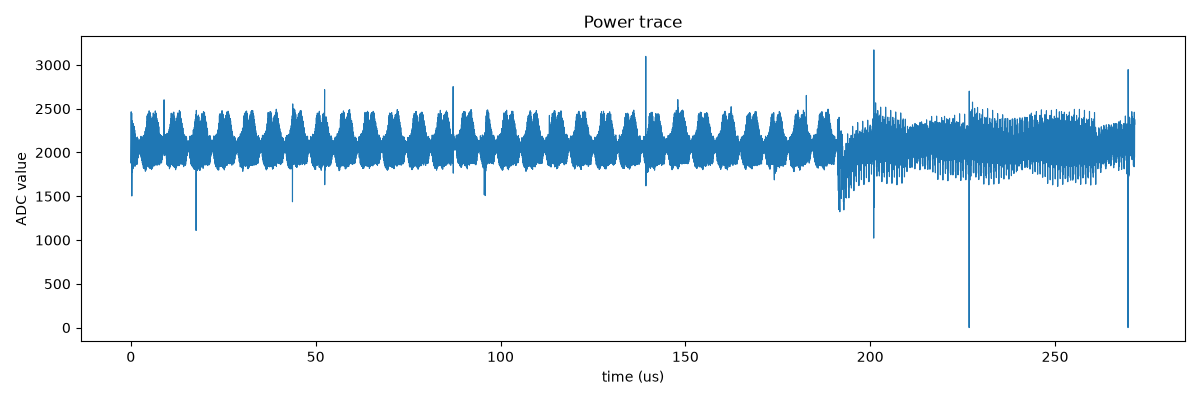

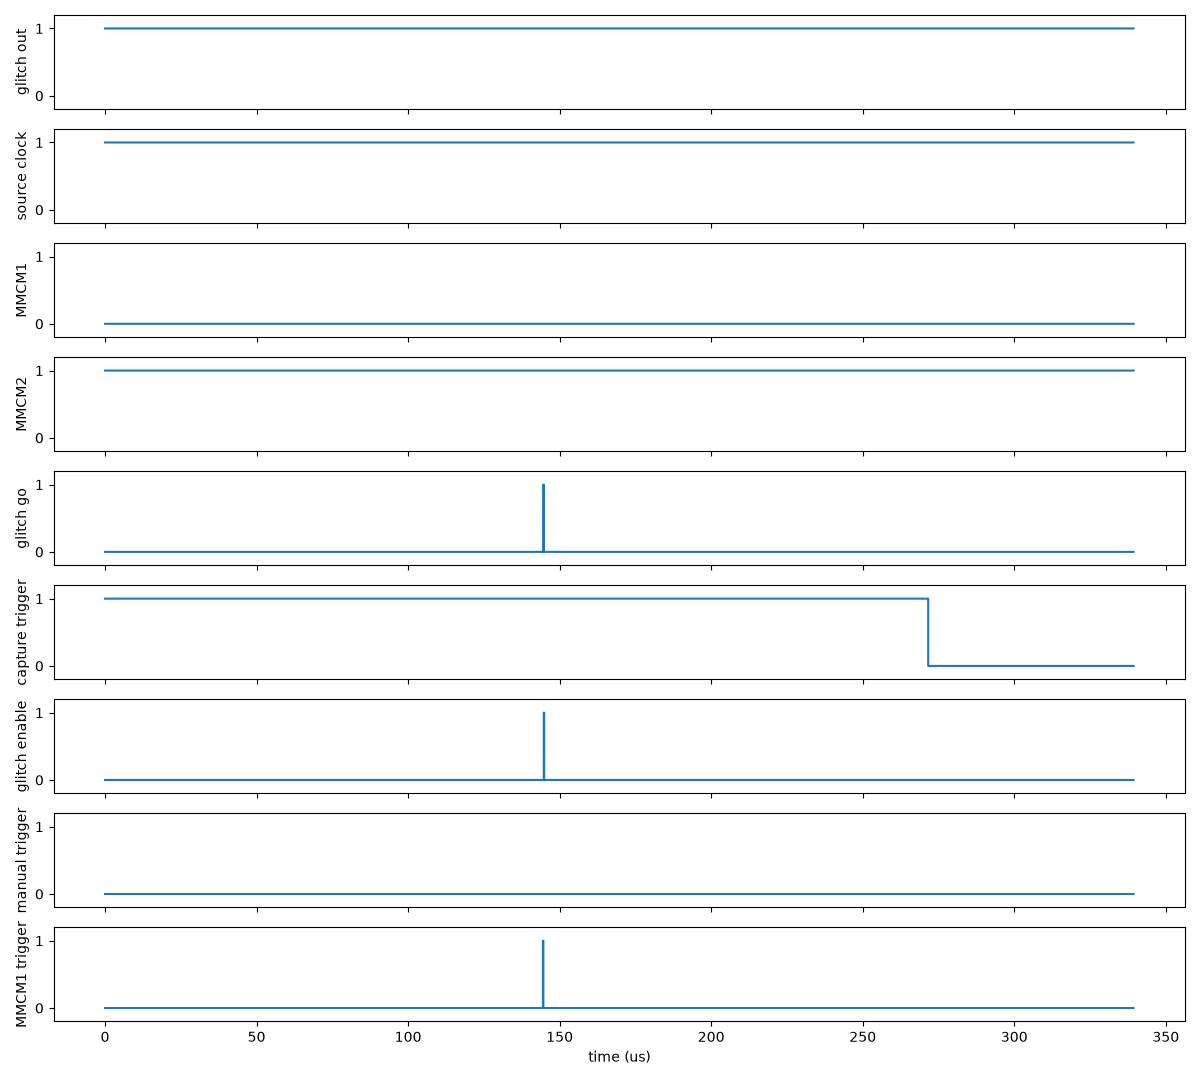

In [27]:
%run "./LibLoadSaveTraces.ipynb"
%run "./LibStm32Boot.ipynb"
%run "./LibPlotting.ipynb"
%run "./LibCalculateGlitchTiming.ipynb"

import chipwhisperer as cw

try:
    scope.dis()
except:
    pass

scope = cw.scope()
scope.default_setup()


size = FLASH_SIZE
# --- get the LA's actual sample rate ---
unit = 'us'
addr = FLASH_BASE
length = 256
debug = False


target = cw.target(scope, cw.targets.SimpleSerial)
scope.io.tio1 = "serial_tx"
scope.io.tio2 = "serial_rx"
scope.io.tio3 = "gpio_high"
set_debug_pin(True)

ser = target.ser
ser.setBaud(BAUD)
ser.setParity("even")

init_logic_analyser_and_adc(scope)

sigs, data, trace = capture_with_la('glitch', addr, length, glitch=True)


plot_power_trace(trace)

plot_la_trace_glitch(scope, sigs)

